# Дообучение с REINFORCE

Текущая модель генерирует действия, замороженная RM предсказывает награду.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "run.py").exists():
    raise RuntimeError("Открой ноутбук из корня проекта.")
RETRAIN = False  # True — обучение; False — сохранённые результаты.
WORK = ROOT / "runs/notebooks" if RETRAIN else ROOT

def run(stage):
    subprocess.run([sys.executable, str(ROOT / "run.py"), stage,
                    "--work-dir", str(WORK)], check=True)


## Запуски

Шесть вариантов × три seeds, по 150 обновлений. Выбор по validation; сравнение с baseline, продолженным обучением и reranking.

In [2]:
if RETRAIN:
    run("rl")
    run("evaluate")
    run("report")
metrics = pd.read_csv(WORK / "results/metrics.csv")
details = json.loads((WORK / "results/details.json").read_text())
print("Выбрана:", details["selection"]["selected"])
display(metrics[metrics.split == "test"][["model", "recall@10", "ndcg@10", "predicted_reward", "auditor_reward"]])

Выбрана: ratio_b0_s27


,model,recall@10,ndcg@10,predicted_reward,auditor_reward
24,popularity,0.01030,0.004874,0.692317,0.645200
25,base,0.03045,0.018507,0.679388,0.655851
26,continued,0.03085,0.018447,0.678619,0.655166
27,rerank_a1,0.03065,0.018527,0.681296,0.656914
28,rerank_a5,0.03265,0.018911,0.687927,0.660712
29,rerank_a10,0.03125,0.018582,0.695083,0.664650
30,ratio_b0_s7,0.03185,0.018512,0.688201,0.660804
31,ratio_b0_s17,0.03205,0.018440,0.688211,0.660669
32,ratio_b0_s27,0.03225,0.018561,0.688390,0.660893
33,ratio_b005_s7,0.03185,0.018533,0.686093,0.659610


## Награда и релевантность

Прогноз RM вырос. Интервал изменения NDCG включает ноль; улучшение релевантности не подтверждено.

,model,mean_duration,seen_fraction,catalog_coverage,top10_exposure_share,between_user_jaccard
24,popularity,168.500000,0.023620,0.0020,1.000000,1.000000
25,base,192.290892,0.110337,0.8032,0.069840,0.006780
26,continued,192.573992,0.112518,0.8174,0.069332,0.006792
27,rerank_a1,191.410533,0.110387,0.8010,0.069535,0.007047
28,rerank_a5,188.512308,0.109995,0.7898,0.072478,0.006915
29,rerank_a10,186.026017,0.108318,0.7684,0.078729,0.007299
30,ratio_b0_s7,187.295917,0.111392,0.7678,0.087802,0.009291
31,ratio_b0_s17,186.998200,0.111248,0.7722,0.087497,0.009015
32,ratio_b0_s27,186.978917,0.111668,0.7690,0.086909,0.009401
33,ratio_b005_s7,188.489708,0.111647,0.7810,0.080658,0.008796


,model,metric,mean,low,high
24,ratio_b0_s27,ndcg10,0.000054,-0.000892,0.001051
25,ratio_b0_s27,recall10,0.001800,-0.000505,0.003800
26,ratio_b0_s27,predicted_reward,0.009002,0.008603,0.009433


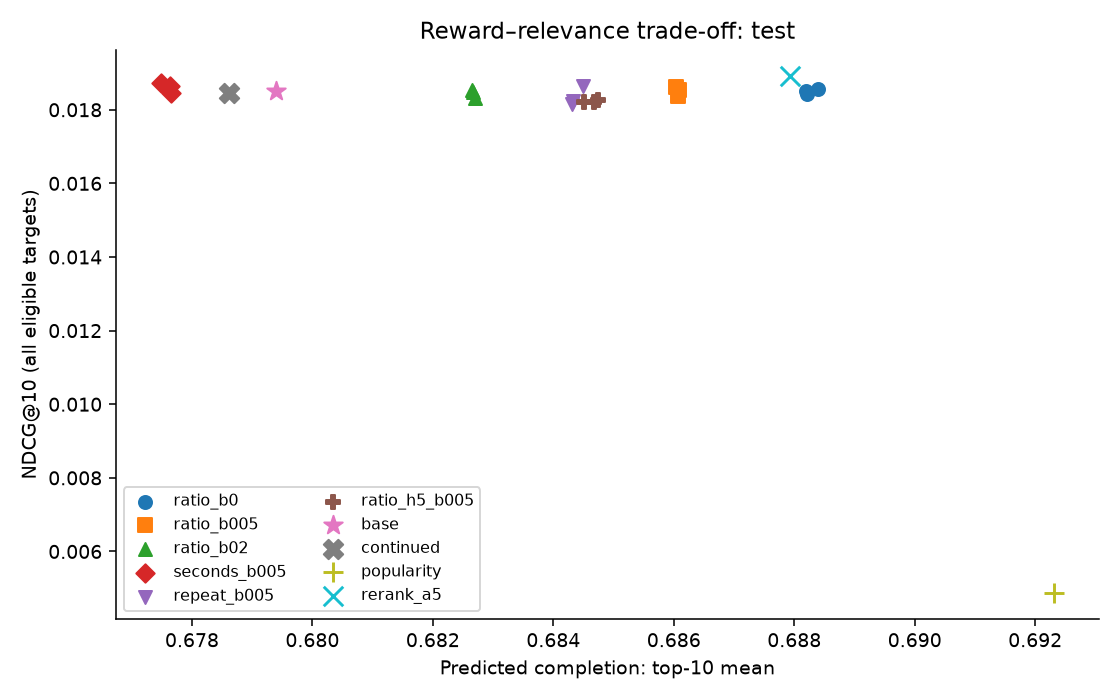

In [3]:
display(metrics[metrics.split == "test"][["model", "mean_duration", "seen_fraction", "catalog_coverage", "top10_exposure_share", "between_user_jaccard"]])
intervals = pd.DataFrame(details["tables"]["confidence_intervals"])
display(intervals[intervals.model == details["selection"]["selected"]])

from IPython.display import Image
plot = WORK / "results/figures/tradeoff.png"
if plot.exists():
    display(Image(filename=str(plot)))

## Пять шагов

Top-5: один проход. Next-5: обновление контекста после каждого трека. unique: запрет дублей, дополнительная диагностика после обнаружения повторов; на выбор модели не влияет.

,model,mode,ndcg@5,predicted_reward,duplicate_fraction
0,base,next5,0.023780,0.688161,0.725597
1,base,top5,0.024258,0.686718,0.000000
2,base,next5_unique,0.024917,0.682335,0.000000
3,ratio_b0_s7,next5,0.013580,0.698772,0.734074
4,ratio_b0_s7,top5,0.021222,0.694726,0.000000
5,ratio_b0_s7,next5_unique,0.015755,0.692904,0.000000
6,ratio_b0_s27,next5,0.013580,0.698946,0.736872
7,ratio_b0_s27,top5,0.021222,0.695010,0.000000
8,ratio_b0_s27,next5_unique,0.015755,0.693300,0.000000
9,ratio_h5_b005_s7,next5,0.016049,0.696725,0.733004


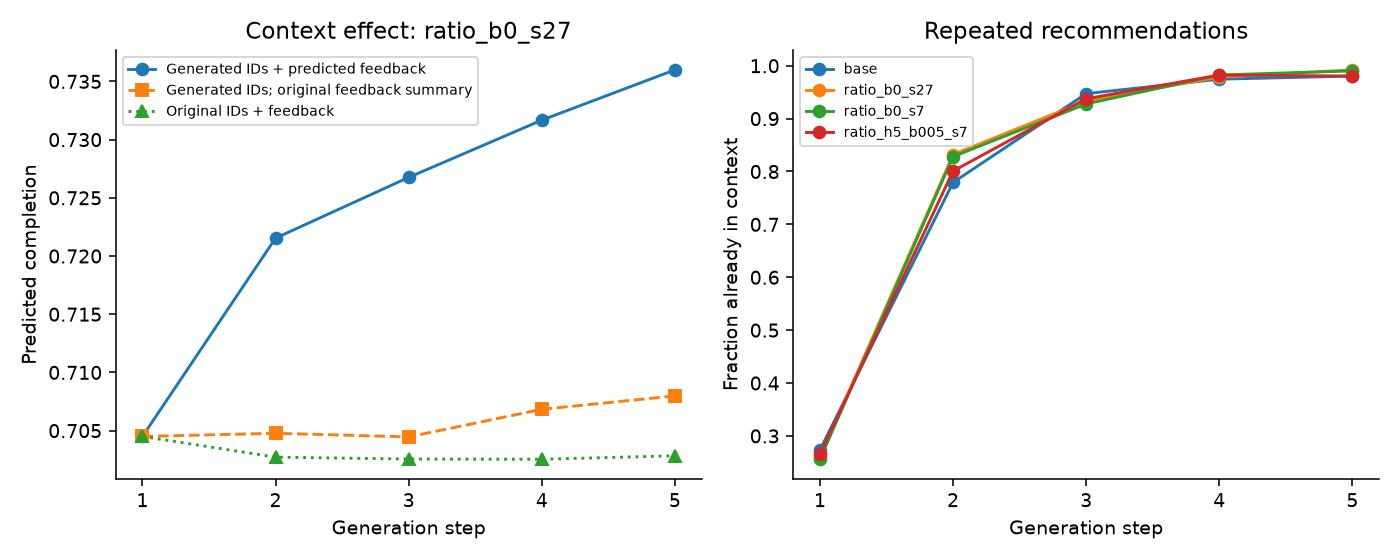

In [4]:
display(pd.DataFrame(details["tables"]["rollout_metrics"])[["model", "mode", "ndcg@5", "predicted_reward", "duplicate_fraction"]])
from IPython.display import Image, display
display(Image(filename=str(WORK / "results/figures/rollouts.png")))

## Вывод

Выдача стала более концентрированной, повторы сохранились. Добавление прогнозов RM в историю повышает её следующие оценки. Реальная возвращаемость пользователей не измерялась.